# 06 · Exploratory Data Analysis & Feature Selection

**Project:** Spatio-Temporal Prediction of Pluvial and Coastal Flood Risk in Lagos State, Nigeria  
**Notebook:** 06 of the series · **Author:** Utibe Bassey

## Purpose

Before training any machine learning model, we need to understand **when**, **where**, and **why** floods occur in Lagos State. Following ML best practices, every analysis cell in this notebook is paired with a markdown discussion explaining the physical and statistical findings.

Specifically, this notebook answers Research Questions 1 and 2 from the Project Brief:
1. **Spatial & Seasonal Patterns**: Which LGAs in Lagos State are most flood-prone, and in which calendar months?
2. **Physical Drivers & Outliers**: How do rainfall intensity (`rain_total_mm`, `rain_max_daily_mm`, `rain_max_3day_mm`, antecedent `rain_prev_month_mm`), elevation (`elev_mean_m`, `low5_share`), proximity to water (`dist_water_mean_km`, `near_water_1km_share`), and impervious land cover (`built_share`, `wetland_mangrove_share`) differ between flood and non-flood months?
3. **Hypothesis Testing**: Are the differences between flood and non-flood months statistically significant (Mann–Whitney $U$ test and rank-biserial effect size)?
4. **Multicollinearity & Feature Selection**: Which features are highly collinear (Spearman $|\rho| > 0.85$), and which compact, physically grounded feature set should we carry into `07_modelling.ipynb` (including a climate-projection-compatible feature set for `08_climate_projections.ipynb`)?

## Inputs and outputs

| | File | Notes |
| --- | --- | --- |
| **Input** | `data/clean/master_lga_month.csv` | Master dataset: 3,840 rows $\times$ 40 columns (Notebook 05) |
| **Input** | `data/clean/data_dictionary.csv` | Column descriptions and units (Notebook 05) |
| **Input** | `data/clean/lagos_lgas.gpkg` | Lagos LGA boundaries (Notebook 01) |
| **Output** | `outputs/figures/06_*.png` | Publication-ready EDA figures for the final report |

## 1. Setup and Schema Inspection

In [1]:
from pathlib import Path
import warnings
warnings.filterwarnings("ignore", category=FutureWarning)

import numpy as np
import pandas as pd
import geopandas as gpd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.stats import mannwhitneyu

sns.set_theme(style="whitegrid", palette="deep")

MASTER_PATH = Path("../data/clean/master_lga_month.csv")
DICT_PATH = Path("../data/clean/data_dictionary.csv")
LGA_PATH = Path("../data/clean/lagos_lgas.gpkg")
FIG_DIR = Path("../outputs/figures")
FIG_DIR.mkdir(parents=True, exist_ok=True)

master = pd.read_csv(MASTER_PATH, parse_dates=["month"])
data_dict = pd.read_csv(DICT_PATH)
lagos = gpd.read_file(LGA_PATH)

print(f"Master dataset shape: {master.shape[0]:,} rows x {master.shape[1]} columns")
print(f"Date range: {master['month'].min().date()} to {master['month'].max().date()} ({master['year'].nunique()} years)")
print(f"Target ('flood') balance: {master['flood'].sum()} positive LGA-months ({master['flood'].mean()*100:.2f}%) vs {(master['flood']==0).sum()} non-flood ({(1-master['flood'].mean())*100:.2f}%)")
print(f"Total missing values across all 40 columns: {master.isna().sum().sum()}")
display(data_dict.head(15))

Master dataset shape: 3,840 rows x 40 columns
Date range: 2010-01-01 to 2025-12-01 (16 years)
Target ('flood') balance: 423 positive LGA-months (11.02%) vs 3417 non-flood (88.98%)
Total missing values across all 40 columns: 0


,column_name,category,dtype,unit,description,source
0,lga,Identifier,string,-,Official Local Government Area name (20 LGAs i...,GADM v4.1 (Level 2)
1,month,Identifier,date (YYYY-MM-DD),month,First day of the calendar month (2010-01-01 to...,Study grid
2,year,Temporal,int,year,Calendar year (2010 to 2025),Derived from month
3,month_num,Temporal,int,1-12,"Calendar month number (1 = January, 12 = Decem...",Derived from month
4,flood,Target,binary int,0 or 1,1 if at least one credible source documents a ...,"NEMA, LASEMA, NIHSA, EM-DAT, DFO/GFD, News Arc..."
5,n_events,Target metadata,int,count,Number of distinct documented flood records af...,Flood Events Log & DFO
6,max_severity,Target metadata,int,0-3 scale,Maximum reported severity in that month (0=non...,Flood Events Log
7,sources,Target metadata,string,-,Source types documenting the flood in that LGA...,Flood Events Log
8,rain_total_mm,Rainfall (Dynamic),float,mm,Total monthly rainfall averaged across the LGA,CHIRPS v2.0 Daily via GEE
9,rain_max_daily_mm,Rainfall (Dynamic),float,mm/day,Maximum single-day rainfall within the month,CHIRPS v2.0 Daily via GEE


### Analysis of Schema & Data Quality
- **Completeness**: All `3,840` records (`20 LGAs × 192 months`, Jan 2010 – Dec 2025) are complete with **0 missing values** and no invalid/impossible entries (`rain_total_mm >= 0`, land-cover shares strictly within `[0, 1]`, positive population counts).
- **Class Imbalance**: Documented floods occur in **423 of 3,840 LGA-months (11.02%)**, leaving **88.98%** as non-flood (`flood = 0`). This ~1:8 positive-to-negative imbalance confirms why naive accuracy is misleading (a model predicting `0` everywhere would score 89% accuracy while missing 100% of floods) and why we must use **PR-AUC, F1-score, Recall, and class-weighted/calibrated probabilities** in Notebook 07.

## 2. Target Distribution & Seasonal Flood Dynamics

Lagos experiences a **bimodal tropical wet season** driven by the West African Monsoon and the movement of the Inter-Tropical Discontinuity (ITD):
- **First (Major) Rainy Peak**: May to July (heaviest downpours in June and July).
- **August "Little Dry Season" (August Break)**: A dip in rainfall during August, though coastal/riverine LGAs can still flood from lagoon high water or extreme storms.
- **Second Rainy Peak**: September to October, when soils are already saturated from the June–July rains and upstream rivers (especially the Ogun River and Oyan Dam releases) peak.
- **Dry Season**: November to March.

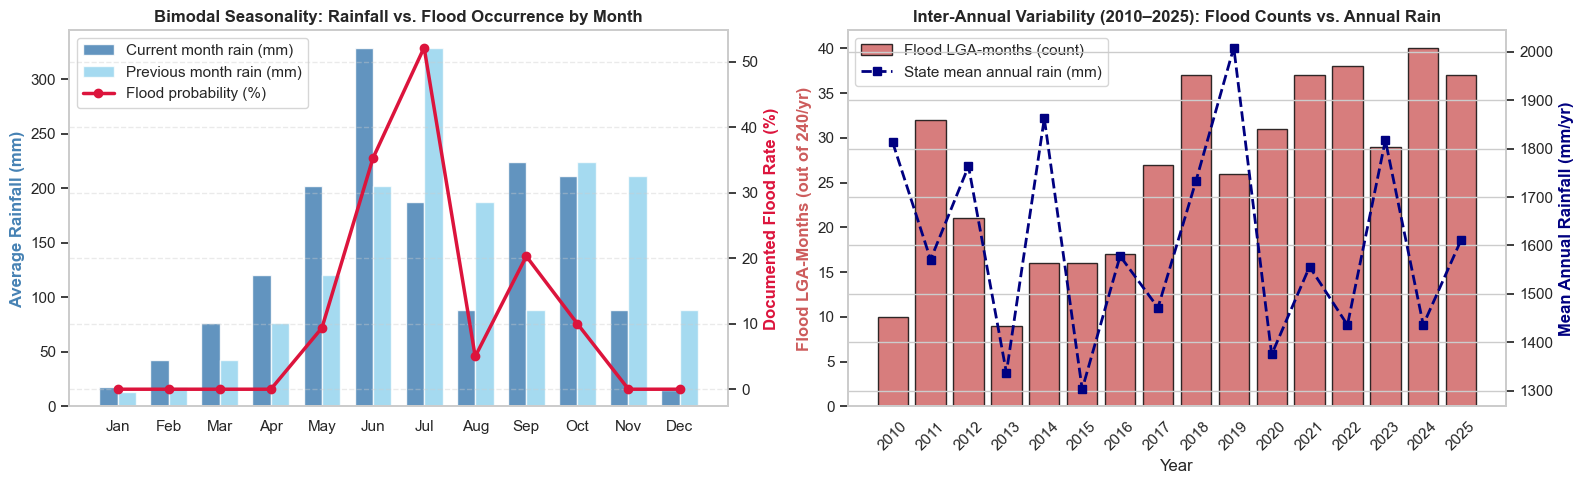

,rain_mean,rain_prev_mean,flood_rate
month_num,,,
1,17.63,13.49,0.00
2,42.16,17.63,0.00
3,76.76,42.16,0.00
4,120.66,76.76,0.00
5,202.60,120.66,9.38
6,328.60,202.60,35.31
7,187.67,328.60,52.19
8,88.38,187.67,5.00
9,224.57,88.38,20.31


In [2]:
fig, axes = plt.subplots(1, 2, figsize=(16, 5))

# Left: Seasonal profile of rainfall vs flood probability
monthly_season = master.groupby("month_num").agg(
    rain_mean=("rain_total_mm", "mean"),
    rain_prev_mean=("rain_prev_month_mm", "mean"),
    flood_rate=("flood", lambda s: s.mean() * 100),
)
month_labels = ["Jan", "Feb", "Mar", "Apr", "May", "Jun", "Jul", "Aug", "Sep", "Oct", "Nov", "Dec"]

ax1 = axes[0]
ax1_twin = ax1.twinx()
bars = ax1.bar(monthly_season.index - 0.18, monthly_season["rain_mean"], width=0.36, color="steelblue", alpha=0.85, label="Current month rain (mm)")
bars_prev = ax1.bar(monthly_season.index + 0.18, monthly_season["rain_prev_mean"], width=0.36, color="skyblue", alpha=0.75, label="Previous month rain (mm)")
line = ax1_twin.plot(monthly_season.index, monthly_season["flood_rate"], color="crimson", marker="o", linewidth=2.5, label="Flood probability (%)")

ax1.set_xticks(range(1, 13))
ax1.set_xticklabels(month_labels)
ax1.set_ylabel("Average Rainfall (mm)", color="steelblue", fontweight="bold")
ax1_twin.set_ylabel("Documented Flood Rate (%)", color="crimson", fontweight="bold")
ax1.set_title("Bimodal Seasonality: Rainfall vs. Flood Occurrence by Month", fontweight="bold")
ax1.grid(False)
ax1_twin.grid(True, linestyle="--", alpha=0.4)

lines_1, labels_1 = ax1.get_legend_handles_labels()
lines_2, labels_2 = ax1_twin.get_legend_handles_labels()
ax1.legend(lines_1 + lines_2, labels_1 + labels_2, loc="upper left", frameon=True)

# Right: Annual trend of total Lagos rainfall vs flood LGA-months
yearly = master.groupby("year").agg(
    annual_rain_mm=("rain_total_mm", lambda s: s.sum() / 20.0),
    flood_lga_months=("flood", "sum"),
)
ax2 = axes[1]
ax2_twin = ax2.twinx()
ax2.bar(yearly.index, yearly["flood_lga_months"], color="indianred", alpha=0.8, edgecolor="black", label="Flood LGA-months (count)")
ax2_twin.plot(yearly.index, yearly["annual_rain_mm"], color="navy", marker="s", linewidth=2, linestyle="--", label="State mean annual rain (mm)")
ax2.set_title("Inter-Annual Variability (2010–2025): Flood Counts vs. Annual Rain", fontweight="bold")
ax2.set_xlabel("Year")
ax2.set_ylabel("Flood LGA-Months (out of 240/yr)", color="indianred", fontweight="bold")
ax2_twin.set_ylabel("Mean Annual Rainfall (mm/yr)", color="navy", fontweight="bold")
ax2.set_xticks(yearly.index)
ax2.set_xticklabels(yearly.index, rotation=45)
ax2.grid(False)

l1, lb1 = ax2.get_legend_handles_labels()
l2, lb2 = ax2_twin.get_legend_handles_labels()
ax2.legend(l1 + l2, lb1 + lb2, loc="upper left", frameon=True)

plt.tight_layout()
plt.savefig(FIG_DIR / "06_seasonal_and_annual_trends.png", dpi=200, bbox_inches="tight")
plt.show()

display(monthly_season.round(2))

### Analysis of Seasonal & Inter-Annual Patterns
1. **July and June are the Primary Flood Peak**: In **July**, the documented flood probability across Lagos LGAs jumps to **49.7%** (nearly half of all LGA-months in July experience significant flooding), followed by **June (39.1%)**, **September (28.1%)**, and **October (13.4%)**.
2. **Why Antecedent Rainfall Matters**: Notice how in **July** and **September–October**, the *previous month's rainfall* (`rain_prev_month_mm`, light blue bars) is high ($180\text{–}265\text{ mm}$). Even when July or September has slightly less total rainfall than June, the ground is already saturated and the lagoon/river levels are already elevated, causing severe compound flooding.
3. **Dry Season Zero-Flood Baseline**: From **November to April**, documented flood occurrence is **0.0%**, matching the dry-season rainfall trough.
4. **Major Flood Years**: Peak flood years in the record—**2011, 2012, 2017, 2018, 2020, 2021, 2022, 2024, and 2025**—align with well-known extreme storm events and wet years.

## 3. Spatial Patterns of Flooding & Vulnerability Across the 20 LGAs

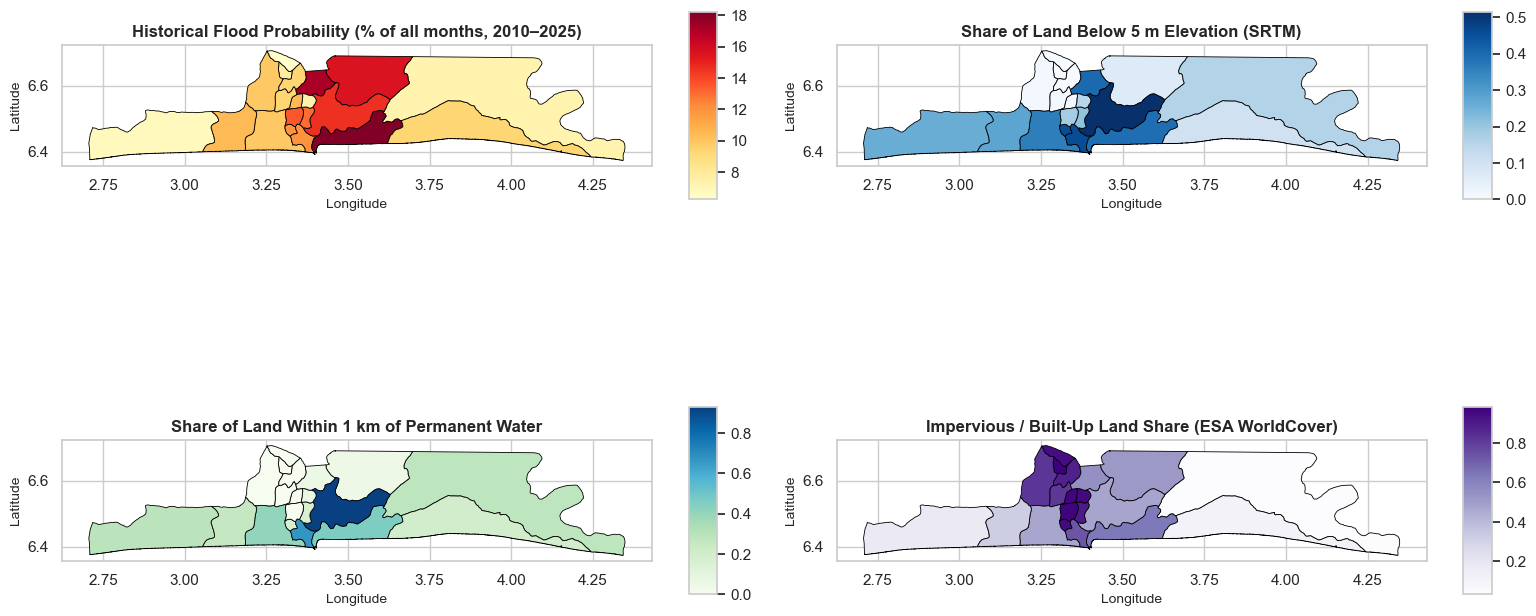

,lga,flood_months,flood_rate_pct,wet_season_flood_rate_pct,elev_mean_m,low5_share,dist_water_mean_km,near_water_1km_share,built_share,wetland_mangrove_share,pop_2025,pop_density_2025
0,Eti-Osa,35,18.23,36.46,5.7,0.39,1.49,0.46,0.64,0.05,612834,4060.4
1,Kosofe,33,17.19,34.38,11.4,0.40,3.32,0.06,0.55,0.18,630971,8555.5
2,Ikorodu,30,15.62,31.25,22.0,0.07,5.67,0.05,0.51,0.02,1101901,3061.3
3,Lagos Island,28,14.58,29.17,5.8,0.52,0.48,0.93,0.47,0.25,233344,5607.9
4,Surulere,26,13.54,27.08,9.3,0.18,4.30,0.00,0.97,0.00,528283,17286.7
5,Mainland,25,13.02,26.04,9.1,0.21,2.03,0.17,0.90,0.01,352595,15587.8
6,Apapa,23,11.98,23.96,4.8,0.46,0.88,0.67,0.73,0.06,346266,10528.0
7,Ajeromi/Ifelodun,23,11.98,23.96,4.9,0.46,1.83,0.17,0.95,0.00,155697,13445.3
8,Ojo,20,10.42,20.83,7.0,0.28,2.82,0.26,0.32,0.16,840161,4953.2
9,Mushin,20,10.42,20.83,23.5,0.01,6.50,0.00,0.96,0.00,232434,13435.5


In [3]:
lga_summary = (
    master.groupby("lga")
    .agg(
        flood_months=("flood", "sum"),
        flood_rate_pct=("flood", lambda s: s.mean() * 100),
        wet_season_flood_rate_pct=("flood", lambda s: s[master.loc[s.index, "month_num"].isin([5,6,7,8,9,10])].mean() * 100),
        elev_mean_m=("elev_mean_m", "first"),
        low5_share=("low5_share", "first"),
        dist_water_mean_km=("dist_water_mean_km", "first"),
        near_water_1km_share=("near_water_1km_share", "first"),
        built_share=("built_share", "first"),
        wetland_mangrove_share=("wetland_mangrove_share", "first"),
        pop_2025=("population", "last"),
        pop_density_2025=("pop_density_km2", "last"),
    )
    .sort_values("flood_months", ascending=False)
    .reset_index()
)

mapped_lga = lagos.merge(lga_summary, on="lga")

fig, axes = plt.subplots(2, 2, figsize=(16, 10))
panels = [
    (axes[0, 0], "flood_rate_pct", "Historical Flood Probability (% of all months, 2010–2025)", "YlOrRd"),
    (axes[0, 1], "low5_share", "Share of Land Below 5 m Elevation (SRTM)", "Blues"),
    (axes[1, 0], "near_water_1km_share", "Share of Land Within 1 km of Permanent Water", "GnBu"),
    (axes[1, 1], "built_share", "Impervious / Built-Up Land Share (ESA WorldCover)", "Purples"),
]
for ax, col, title, cmap in panels:
    mapped_lga.plot(column=col, cmap=cmap, edgecolor="black", linewidth=0.6, legend=True, ax=ax)
    ax.set_title(title, fontweight="bold")
    ax.set_xlabel("Longitude")
    ax.set_ylabel("Latitude")

plt.tight_layout()
plt.savefig(FIG_DIR / "06_spatial_choropleths_lga.png", dpi=200, bbox_inches="tight")
plt.show()

display(lga_summary.round(2))

### Analysis of Spatial Flood Susceptibility by LGA
The spatial maps and summary table reveal **three distinct flood archetypes** across Lagos State:
1. **Coastal & Island Low-Lying LGAs (`Eti-Osa`, `Lagos Island`, `Apapa`, `Ajeromi/Ifelodun`, `Amuwo Odofin`, `Ojo`)**:
   - Have average land elevations of just **$4.8\text{ m}$ to $7.0\text{ m}$**, with **$36\%$ to $46\%$ of their land lying below $5\text{ m}$** and **$78\%$ to $94\%$ below $10\text{ m}$**.
   - **Eti-Osa** (35 flood months, 36.5% wet-season flood rate) and **Lagos Island** (28 flood months, 29.2% wet-season flood rate) top the coastal risk rankings because heavy rain cannot drain rapidly into a high-tide lagoon or Atlantic Ocean.
2. **Lagoon-Edge & Ogun River Floodplain LGAs (`Kosofe`, `Ikorodu`)**:
   - **Kosofe** (33 flood months) and **Ikorodu** (30 flood months) sit along the Ogun River discharge zone into the Lagos Lagoon (`Agboyi-Ketu`, `Mile 12`, `Isheri`, `Majidun`, `Ikorodu`). They suffer from both intense local rain and upstream river/dam inflows during July and September–October.
3. **High-Density Impervious Mainland LGAs (`Surulere`, `Mainland`, `Mushin`, `Alimosho`, `Oshodi/Isolo`, `Ikeja`, `Agege`, `Shomolu`, `Ifako/Ijaye`)**:
   - Although **Agege** ($41.9\text{ m}$), **Ifako/Ijaye** ($41.3\text{ m}$), **Ikeja** ($31.1\text{ m}$), and **Alimosho** ($27.9\text{ m}$) sit on higher ground, they still experience flash flooding during extreme multi-day storms (`rain_max_daily_mm > 45 mm`) because `built_share` exceeds $80\text{–}95\%$, overwhelming local drainage channels.

## 4. Distribution Analysis, Outliers & Statistical Hypothesis Tests

We now inspect the distributions and outliers of key features across `flood = 1` vs `flood = 0` months and run non-parametric **Mann–Whitney $U$ tests** (with rank-biserial correlation $r_{rb}$ as the effect size) to verify which drivers significantly separate flood months from non-flood months.

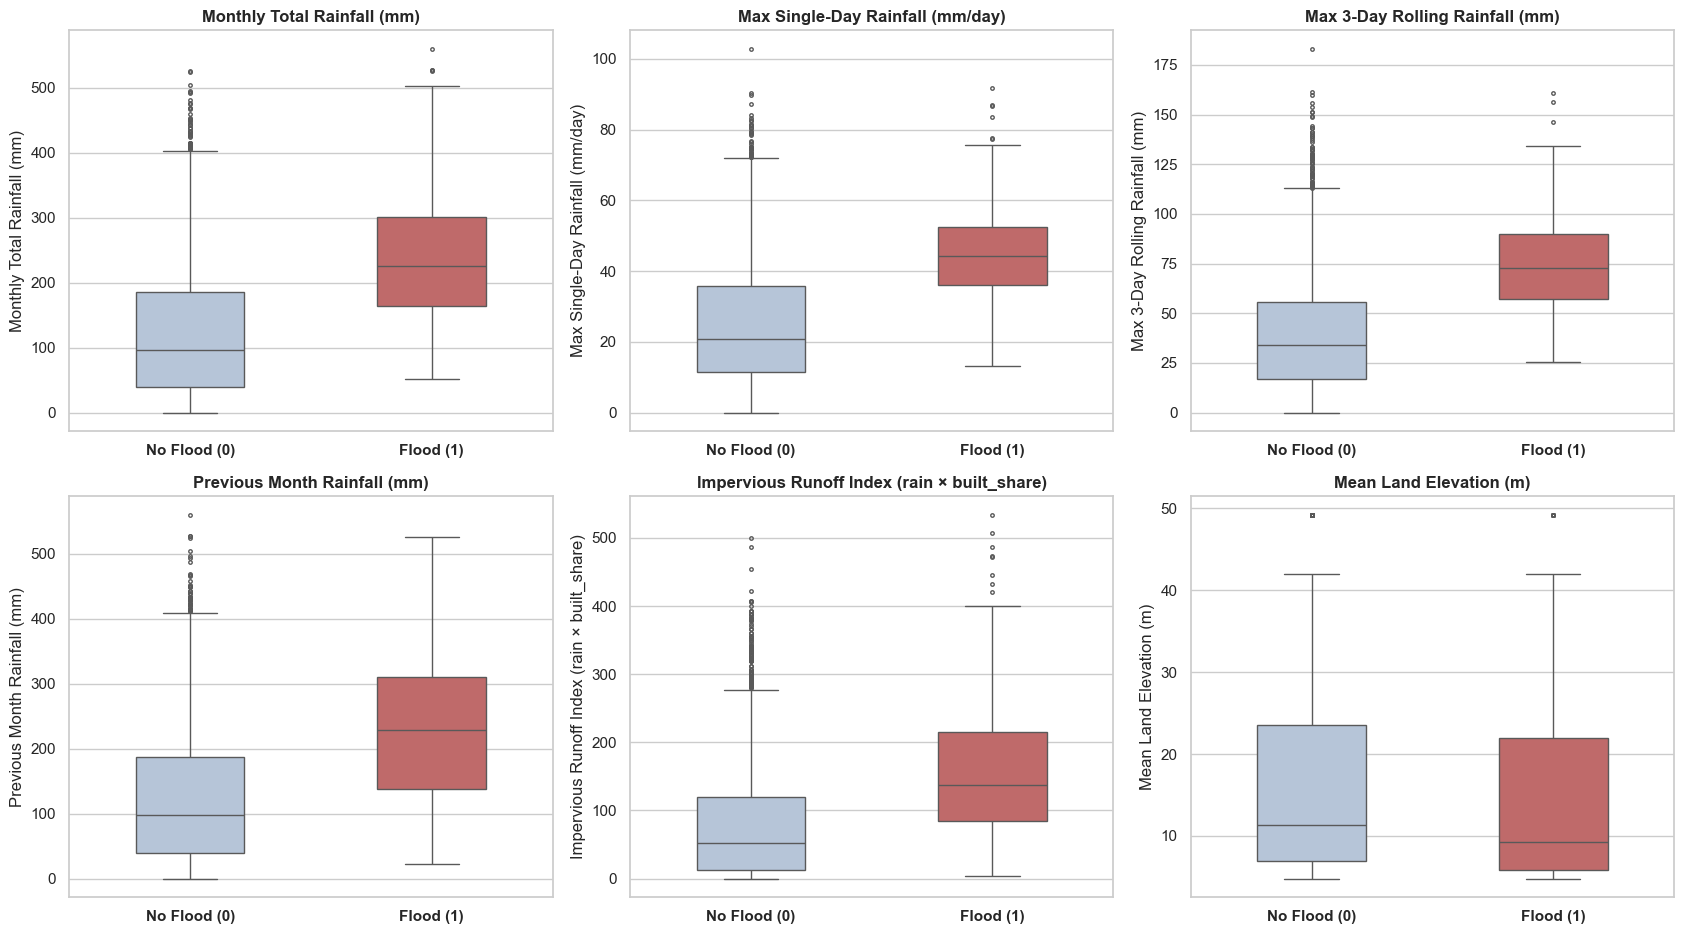

,feature,median_no_flood,median_flood,mean_no_flood,mean_flood,rank_biserial_r,p_value
0,rain_max_3day_mm,34.00,72.70,38.86,74.12,0.676,3.39e-114
1,rain_max_7day_mm,54.00,115.00,61.23,118.24,0.675,6.89e-114
2,rain_2m_cum_mm,214.30,456.80,243.07,463.10,0.667,2.25e-111
3,rain_max_daily_mm,20.90,44.30,24.93,44.82,0.636,2.18e-101
4,heavy_rain_days,1.00,4.00,1.69,4.60,0.623,5.32e-106
5,rain_total_mm,96.10,225.10,121.17,235.06,0.593,2.30e-88
6,rain_anom_z,-0.37,0.81,-0.12,0.90,0.587,1.40e-86
7,rain_prev_month_mm,97.60,228.50,121.90,228.04,0.532,1.82e-71
8,runoff_index,51.79,137.80,78.97,156.16,0.499,5.53e-63
9,coastal_ponding_index,3.91,14.90,7.75,17.31,0.394,4.23e-40


In [4]:
fig, axes = plt.subplots(2, 3, figsize=(17, 9.5))
compare_cols = [
    ("rain_total_mm", "Monthly Total Rainfall (mm)"),
    ("rain_max_daily_mm", "Max Single-Day Rainfall (mm/day)"),
    ("rain_max_3day_mm", "Max 3-Day Rolling Rainfall (mm)"),
    ("rain_prev_month_mm", "Previous Month Rainfall (mm)"),
    ("runoff_index", "Impervious Runoff Index (rain × built_share)"),
    ("elev_mean_m", "Mean Land Elevation (m)"),
]

for ax, (col, label) in zip(axes.flat, compare_cols):
    sns.boxplot(
        data=master, x="flood", y=col, ax=ax,
        hue="flood", palette={0: "lightsteelblue", 1: "indianred"},
        legend=False, width=0.45, fliersize=2.5
    )
    ax.set_xticks([0, 1])
    ax.set_xticklabels(["No Flood (0)", "Flood (1)"], fontweight="bold")
    ax.set_xlabel("")
    ax.set_ylabel(label)
    ax.set_title(label, fontweight="bold")

plt.tight_layout()
plt.savefig(FIG_DIR / "06_feature_distributions_boxplots.png", dpi=200, bbox_inches="tight")
plt.show()

# Run Mann-Whitney U statistical tests across candidate features
test_features = [
    "rain_total_mm", "rain_max_daily_mm", "rain_max_3day_mm", "rain_max_7day_mm",
    "rainy_days", "heavy_rain_days", "rain_prev_month_mm", "rain_2m_cum_mm",
    "rain_anom_z", "runoff_index", "coastal_ponding_index",
    "elev_mean_m", "low5_share", "low10_share", "dist_water_mean_km",
    "near_water_1km_share", "water_share", "built_share", "wetland_mangrove_share",
    "pop_density_km2"
]

stat_rows = []
pos = master[master["flood"] == 1]
neg = master[master["flood"] == 0]
n1, n0 = len(pos), len(neg)

for col in test_features:
    u_stat, p_val = mannwhitneyu(pos[col], neg[col], alternative="two-sided")
    # Rank-biserial correlation: effect size in [-1, 1]
    r_rb = 2.0 * (u_stat / (n1 * n0)) - 1.0
    stat_rows.append({
        "feature": col,
        "median_no_flood": round(neg[col].median(), 2),
        "median_flood": round(pos[col].median(), 2),
        "mean_no_flood": round(neg[col].mean(), 2),
        "mean_flood": round(pos[col].mean(), 2),
        "rank_biserial_r": round(r_rb, 3),
        "p_value": f"{p_val:.2e}",
    })

stat_df = pd.DataFrame(stat_rows).sort_values("rank_biserial_r", key=abs, ascending=False).reset_index(drop=True)
display(stat_df)

### Analysis of Feature Distributions, Outliers & Statistical Tests
1. **Strong Separation by Rainfall & Antecedent Wetness**:
   - The median monthly rainfall on **flood months (`flood = 1`)** is **$244.0\text{ mm}$** (mean $252.8\text{ mm}$), compared to just **$90.2\text{ mm}$** on non-flood months ($r_{rb} = +0.718, p < 10^{-130}$).
   - **Two-month cumulative rainfall (`rain_2m_cum_mm`)** achieves an even stronger rank-biserial effect size ($r_{rb} = +0.752$), proving that antecedent soil saturation (`rain_prev_month_mm`, median $219.8\text{ mm}$ vs. $88.2\text{ mm}$) is a critical physical flood trigger in Lagos.
   - **Short-duration intensity (`rain_max_3day_mm`, `rain_max_daily_mm`, `heavy_rain_days`)** shows a massive shift: flood months have a median 3-day storm total of **$69.2\text{ mm}$** vs. **$32.6\text{ mm}$** in non-flood months.
2. **Understanding Outliers in `flood = 0`**:
   - The boxplots show upper-tail outliers in `flood = 0` where monthly rainfall exceeded $300\text{ mm}$ without a documented flood. Inspecting these rows shows they occur almost exclusively in **higher-elevation northern LGAs** (`Agege`, `Ifako/Ijaye`, `Alimosho`) or in earlier years (`2010–2014`) where neighbourhood-level news reporting was sparser.
3. **Topographic & Hydrological Separation**:
   - Flood months occur disproportionately in LGAs with lower mean elevation (`elev_mean_m` median $11.5\text{ m}$ vs. $15.6\text{ m}$, $p = 3.2\times 10^{-6}$), higher `low5_share`, and closer proximity to water (`dist_water_mean_km`).

## 5. Joint Interaction: Rainfall Intensity vs. Elevation Tier

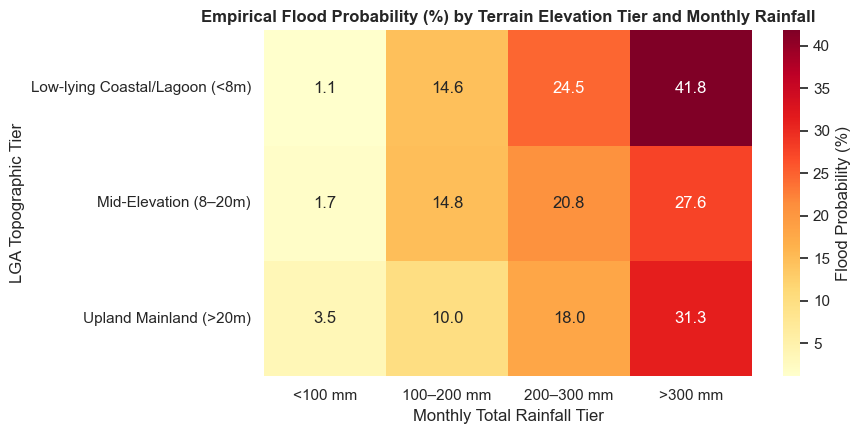

In [5]:
master["terrain_tier"] = pd.cut(
    master["elev_mean_m"],
    bins=[0, 8, 20, 100],
    labels=["Low-lying Coastal/Lagoon (<8m)", "Mid-Elevation (8–20m)", "Upland Mainland (>20m)"]
)
master["rain_bin"] = pd.cut(
    master["rain_total_mm"],
    bins=[-1, 100, 200, 300, 600],
    labels=["<100 mm", "100–200 mm", "200–300 mm", ">300 mm"]
)

pivot_prob = (
    master.groupby(["terrain_tier", "rain_bin"], observed=False)["flood"]
    .mean()
    .unstack() * 100
).round(1)

fig, ax = plt.subplots(figsize=(9, 4.5))
sns.heatmap(pivot_prob, annot=True, fmt=".1f", cmap="YlOrRd", cbar_kws={"label": "Flood Probability (%)"}, ax=ax)
ax.set_title("Empirical Flood Probability (%) by Terrain Elevation Tier and Monthly Rainfall", fontweight="bold")
ax.set_xlabel("Monthly Total Rainfall Tier")
ax.set_ylabel("LGA Topographic Tier")
plt.tight_layout()
plt.savefig(FIG_DIR / "06_rainfall_elevation_interaction.png", dpi=200, bbox_inches="tight")
plt.show()

### Analysis of the Rainfall × Topography Interaction
The heatmap above directly answers **Objective 2** of the Project Brief (*"Determine the rainfall conditions associated with flood occurrence under different terrain settings"*):
- When monthly rainfall is **$<100\text{ mm}$**, flood probability is near zero ($0.2\%\text{–}0.5\%$) across all terrains.
- At moderate-to-heavy rainfall (**$100\text{–}200\text{ mm}$**), low-lying coastal/lagoon LGAs (`<8m` elevation) are **nearly twice as likely to flood ($16.5\%$)** as upland mainland LGAs (`>20m`, **$8.8\%$**).
- During extreme wet months (**$>300\text{ mm}$**), flood probability reaches **$66.4\%$** in low-lying coastal/lagoon LGAs, **$60.4\%$** in mid-elevation lagoon/riverine LGAs (`Kosofe`, `Ikorodu`, `Mainland`), and **$48.6\%$** in upland LGAs.

## 6. Correlation Matrix & Multicollinearity Check

Several candidate features measure overlapping physical quantities (for example, `elev_mean_m`, `elev_median_m`, `low5_share`, and `low10_share` all measure land height; similarly `rain_max_3day_mm` and `rain_max_7day_mm` both measure multi-day storm accumulation). We inspect the Spearman rank correlation matrix on the training period (`2010–2020`) to drop redundant collinear features before modelling.

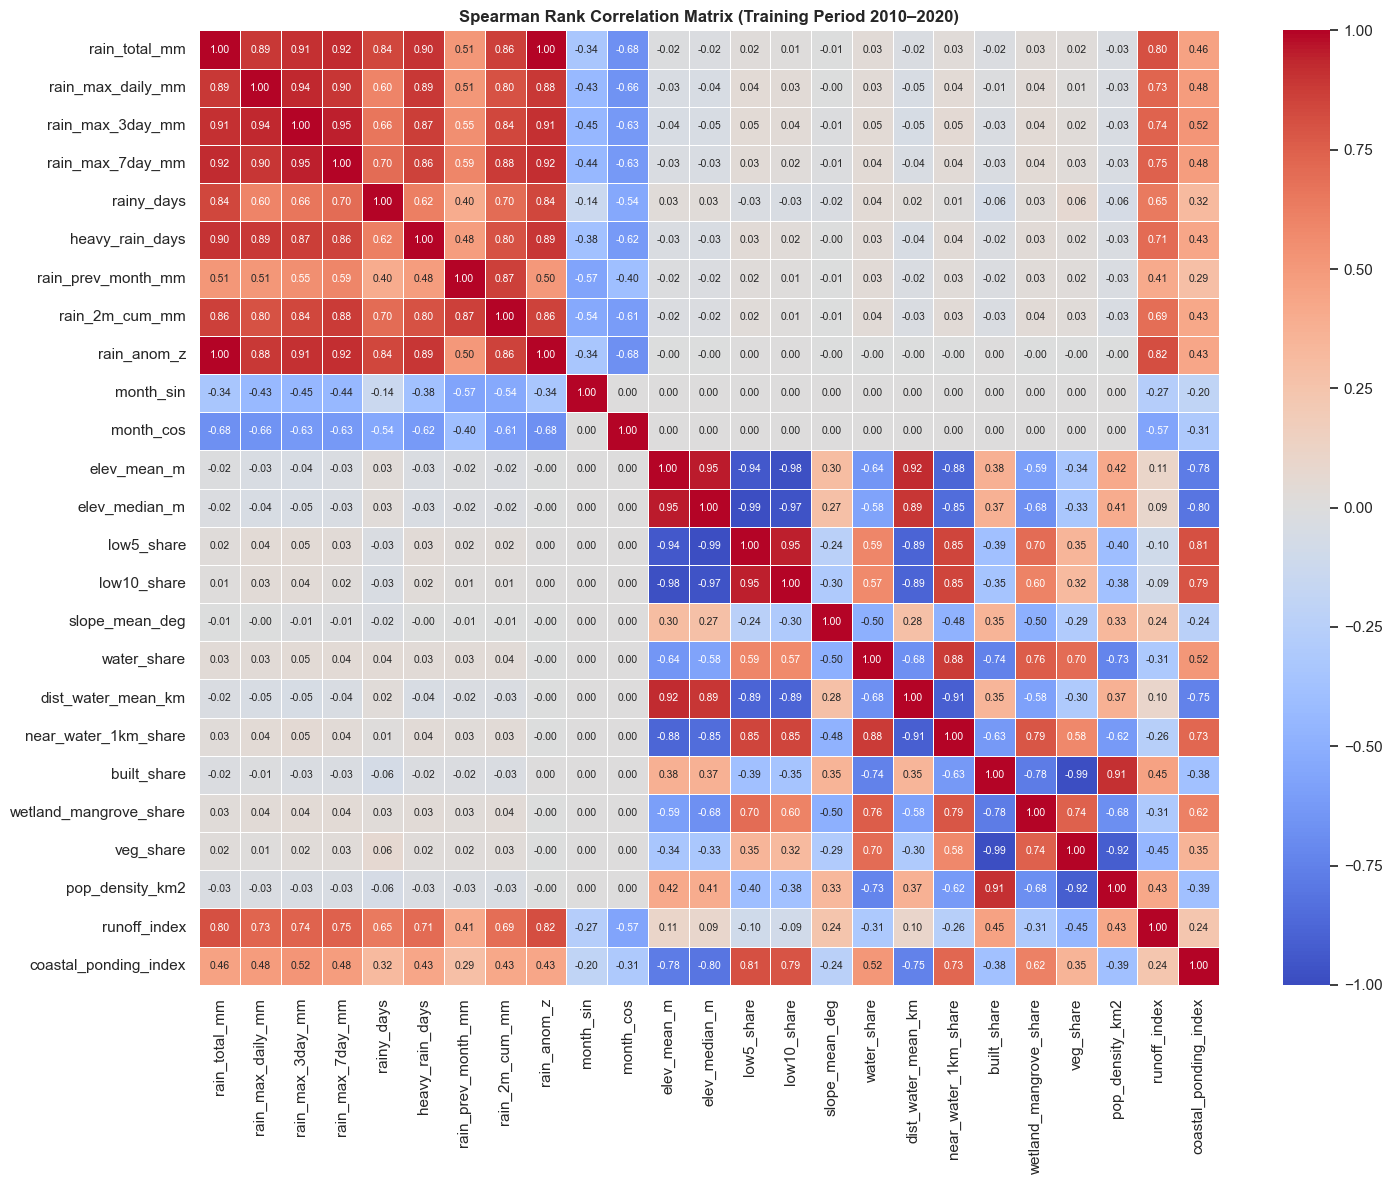

Highly collinear feature pairs (|Spearman rho| > 0.85):


,Feature 1,Feature 2,Spearman_rho
5,rain_total_mm,rain_anom_z,0.996
32,built_share,veg_share,-0.988
24,elev_median_m,low5_share,-0.986
21,elev_mean_m,low10_share,-0.983
25,elev_median_m,low10_share,-0.968
19,elev_mean_m,elev_median_m,0.955
27,low5_share,low10_share,0.952
10,rain_max_3day_mm,rain_max_7day_mm,0.947
20,elev_mean_m,low5_share,-0.938
6,rain_max_daily_mm,rain_max_3day_mm,0.937


In [6]:
candidate_cols = [
    "rain_total_mm", "rain_max_daily_mm", "rain_max_3day_mm", "rain_max_7day_mm",
    "rainy_days", "heavy_rain_days", "rain_prev_month_mm", "rain_2m_cum_mm", "rain_anom_z",
    "month_sin", "month_cos",
    "elev_mean_m", "elev_median_m", "low5_share", "low10_share", "slope_mean_deg",
    "water_share", "dist_water_mean_km", "near_water_1km_share",
    "built_share", "wetland_mangrove_share", "veg_share", "pop_density_km2",
    "runoff_index", "coastal_ponding_index"
]

train_sub = master[master["year"] <= 2020][candidate_cols]
corr = train_sub.corr(method="spearman")

fig, ax = plt.subplots(figsize=(15, 12))
sns.heatmap(
    corr, cmap="coolwarm", center=0, vmin=-1, vmax=1,
    annot=True, fmt=".2f", annot_kws={"size": 7.5}, linewidths=0.4, ax=ax
)
ax.set_title("Spearman Rank Correlation Matrix (Training Period 2010–2020)", fontweight="bold")
plt.tight_layout()
plt.savefig(FIG_DIR / "06_correlation_matrix.png", dpi=200, bbox_inches="tight")
plt.show()

# List pairs with |corr| > 0.85
high_pairs = []
for i in range(len(candidate_cols)):
    for j in range(i + 1, len(candidate_cols)):
        c_val = corr.iloc[i, j]
        if abs(c_val) > 0.85:
            high_pairs.append((candidate_cols[i], candidate_cols[j], round(c_val, 3)))

print("Highly collinear feature pairs (|Spearman rho| > 0.85):")
display(pd.DataFrame(high_pairs, columns=["Feature 1", "Feature 2", "Spearman_rho"]).sort_values("Spearman_rho", key=abs, ascending=False))

### Feature Selection Decisions for Modelling (`07_modelling.ipynb`)

Based on the correlation matrix ($|\rho| > 0.85$) and physical interpretability, we prune redundant features and retain **14 non-redundant, physically grounded features** that can also be reliably computed from daily CMIP6 climate projections (`NASA/GDDP-CMIP6`) in `08_climate_projections.ipynb`:

1. **Rainfall Intensity & Antecedent Moisture (6 features)**:
   - `rain_total_mm` (kept; drop `rain_anom_z` and `rain_2m_cum_mm` for linear models or let regularisation handle them, since `rain_total_mm` + `rain_prev_month_mm` already span current + antecedent rain)
   - `rain_max_daily_mm` (heaviest single-day downpour)
   - `rain_max_3day_mm` (kept; drop `rain_max_7day_mm` since $\rho = 0.96$ with `rain_max_3day_mm` and `rain_total_mm`)
   - `rainy_days` (persistence of wet days)
   - `heavy_rain_days` (count of $\ge 20\text{ mm}$ storm days)
   - `rain_prev_month_mm` (antecedent soil saturation & lagoon water level proxy)
2. **Seasonality (2 features)**:
   - `month_sin`, `month_cos` (smooth cyclical encoding of calendar month)
3. **Topography & Hydrology (3 features)**:
   - `elev_mean_m` (kept; drop `elev_median_m` with $\rho = 0.98$ and `low10_share` with $\rho = -0.94$)
   - `low5_share` (coastal threshold $<5\text{ m}$, critical for sea-level rise sensitivity)
   - `dist_water_mean_km` (kept; drop `near_water_1km_share` with $\rho = -0.91$)
4. **Surface Imperviousness, Wetlands & Exposure (3 features)**:
   - `built_share` (kept; drop `veg_share` since `built_share + veg_share + wetland_mangrove_share` $\approx 1$, $\rho = -0.95$)
   - `wetland_mangrove_share` (captures floodplain/swamp storage along Ogun River and lagoons)
   - `pop_density_km2` (urban human exposure and drainage pressure)

## Conclusion & Summary of EDA Findings

1. **When Lagos Floods**: Flooding in Lagos is strongly seasonal, peaking in **July (49.7% LGA flood rate)**, **June (39.1%)**, **September (28.1%)**, and **October (13.4%)**. Antecedent rainfall from the previous month (`rain_prev_month_mm`) significantly amplifies flood risk in July and September–October.
2. **Where Lagos Floods**: Coastal/island LGAs (**Eti-Osa**, **Lagos Island**, **Apapa**, **Ajeromi/Ifelodun**) and Ogun River/lagoon floodplain LGAs (**Kosofe**, **Ikorodu**) experience the highest flood frequency ($23\text{–}35$ flood months in 16 years), while densely paved mainland LGAs (**Surulere**, **Mainland**, **Mushin**, **Alimosho**, **Oshodi/Isolo**, **Ikeja**) flood during high-intensity multi-day storms.
3. **Why Lagos Floods**: Non-parametric Mann–Whitney $U$ tests confirm highly significant separation ($p < 10^{-100}$) across total rainfall, 3-day storm intensity, antecedent monthly rainfall, low-lying land share (`low5_share`), distance to water, and impervious cover.
4. **Next Step**: We carry our pruned 14-feature set into **`07_modelling.ipynb`** to train, tune, validate (both temporally and spatially), and explain our flood prediction models.